# Import libraries

In [1]:
# Import pandas, numpy, and matplotlib
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# seaborn is a data visualization library built on matplotlib
import seaborn as sns

# set the plotting style
sns.set_style("whitegrid")

# Model preprocessing
from sklearn.preprocessing import StandardScaler

# Modeling
import statsmodels.formula.api as smf
import statsmodels.api as sm

# Model metrics and analysis
from sklearn.metrics import r2_score, mean_squared_error, mean_absolute_error
from statsmodels.stats.anova import anova_lm

# Load clean data

In [2]:
df = pd.read_csv("/Users/kelsie/Desktop/SeattleU/DATA5100/DATA5100-education/data/education_clean.csv")

In [3]:
df.head()

,id,rate_unemployment,percent_college,percent_married,median_income,average_act,percent_lunch,year,state,zip_code,school_type,school_level,charter,teachers
0,100001600143,0.117962,0.445283,0.346495,42820.0,20.433455,0.066901,2016-2017,DE,19804,Regular School,High,Yes,25.0
1,100008000024,0.063984,0.662765,0.767619,89320.0,19.498168,0.112412,2016-2017,DE,19709,Regular School,High,No,87.0
2,100008000225,0.056460,0.701864,0.713090,84140.0,19.554335,0.096816,2016-2017,DE,19709,Regular School,High,No,95.0
3,100017000029,0.044739,0.692062,0.641283,56500.0,17.737485,0.296960,2016-2017,DE,19958,Regular School,High,No,98.0
4,100018000040,0.077014,0.640060,0.834402,54015.0,18.245421,0.262641,2016-2017,DE,19934,Regular School,High,No,134.0


# Exploratory data analysis

## Examine distributions and relationships

### Plot the correlation matrix of the numerical variables in the data to explore relationships between the variables.

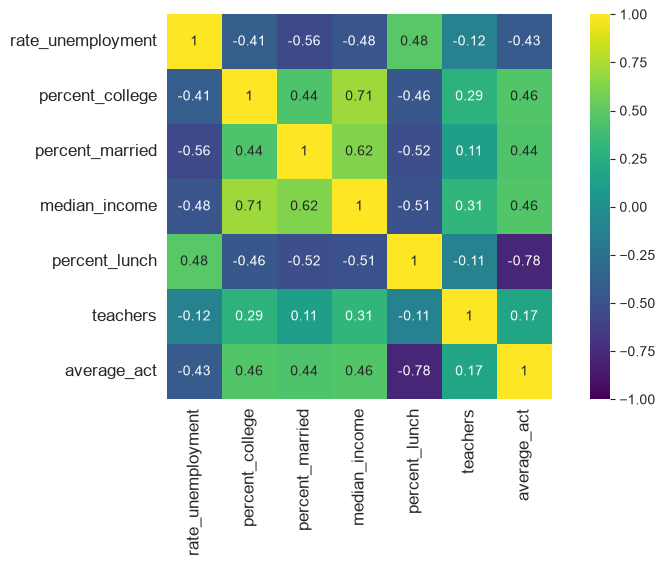

In [4]:
predictor_variables = [
    'rate_unemployment', 
    'percent_college', 
    'percent_married', 
    'median_income', 
    'percent_lunch', 
    'state',
    'teachers'
]

numerical_predictors = df[predictor_variables].select_dtypes(include = 'number').columns.to_list()

corr_matrix = df[numerical_predictors + ['average_act']].corr()

plt.figure(figsize = (10, 5))

sns.heatmap(
    corr_matrix, vmax = 1, vmin = -1, square = True, annot = True, cmap = 'viridis'
)

plt.tick_params(labelsize = 12)

We will look at the correlation between average_act and the predictor variables, as well as the correlation among those predictor variables.

### Make pair plots to explore relationships between the variables.

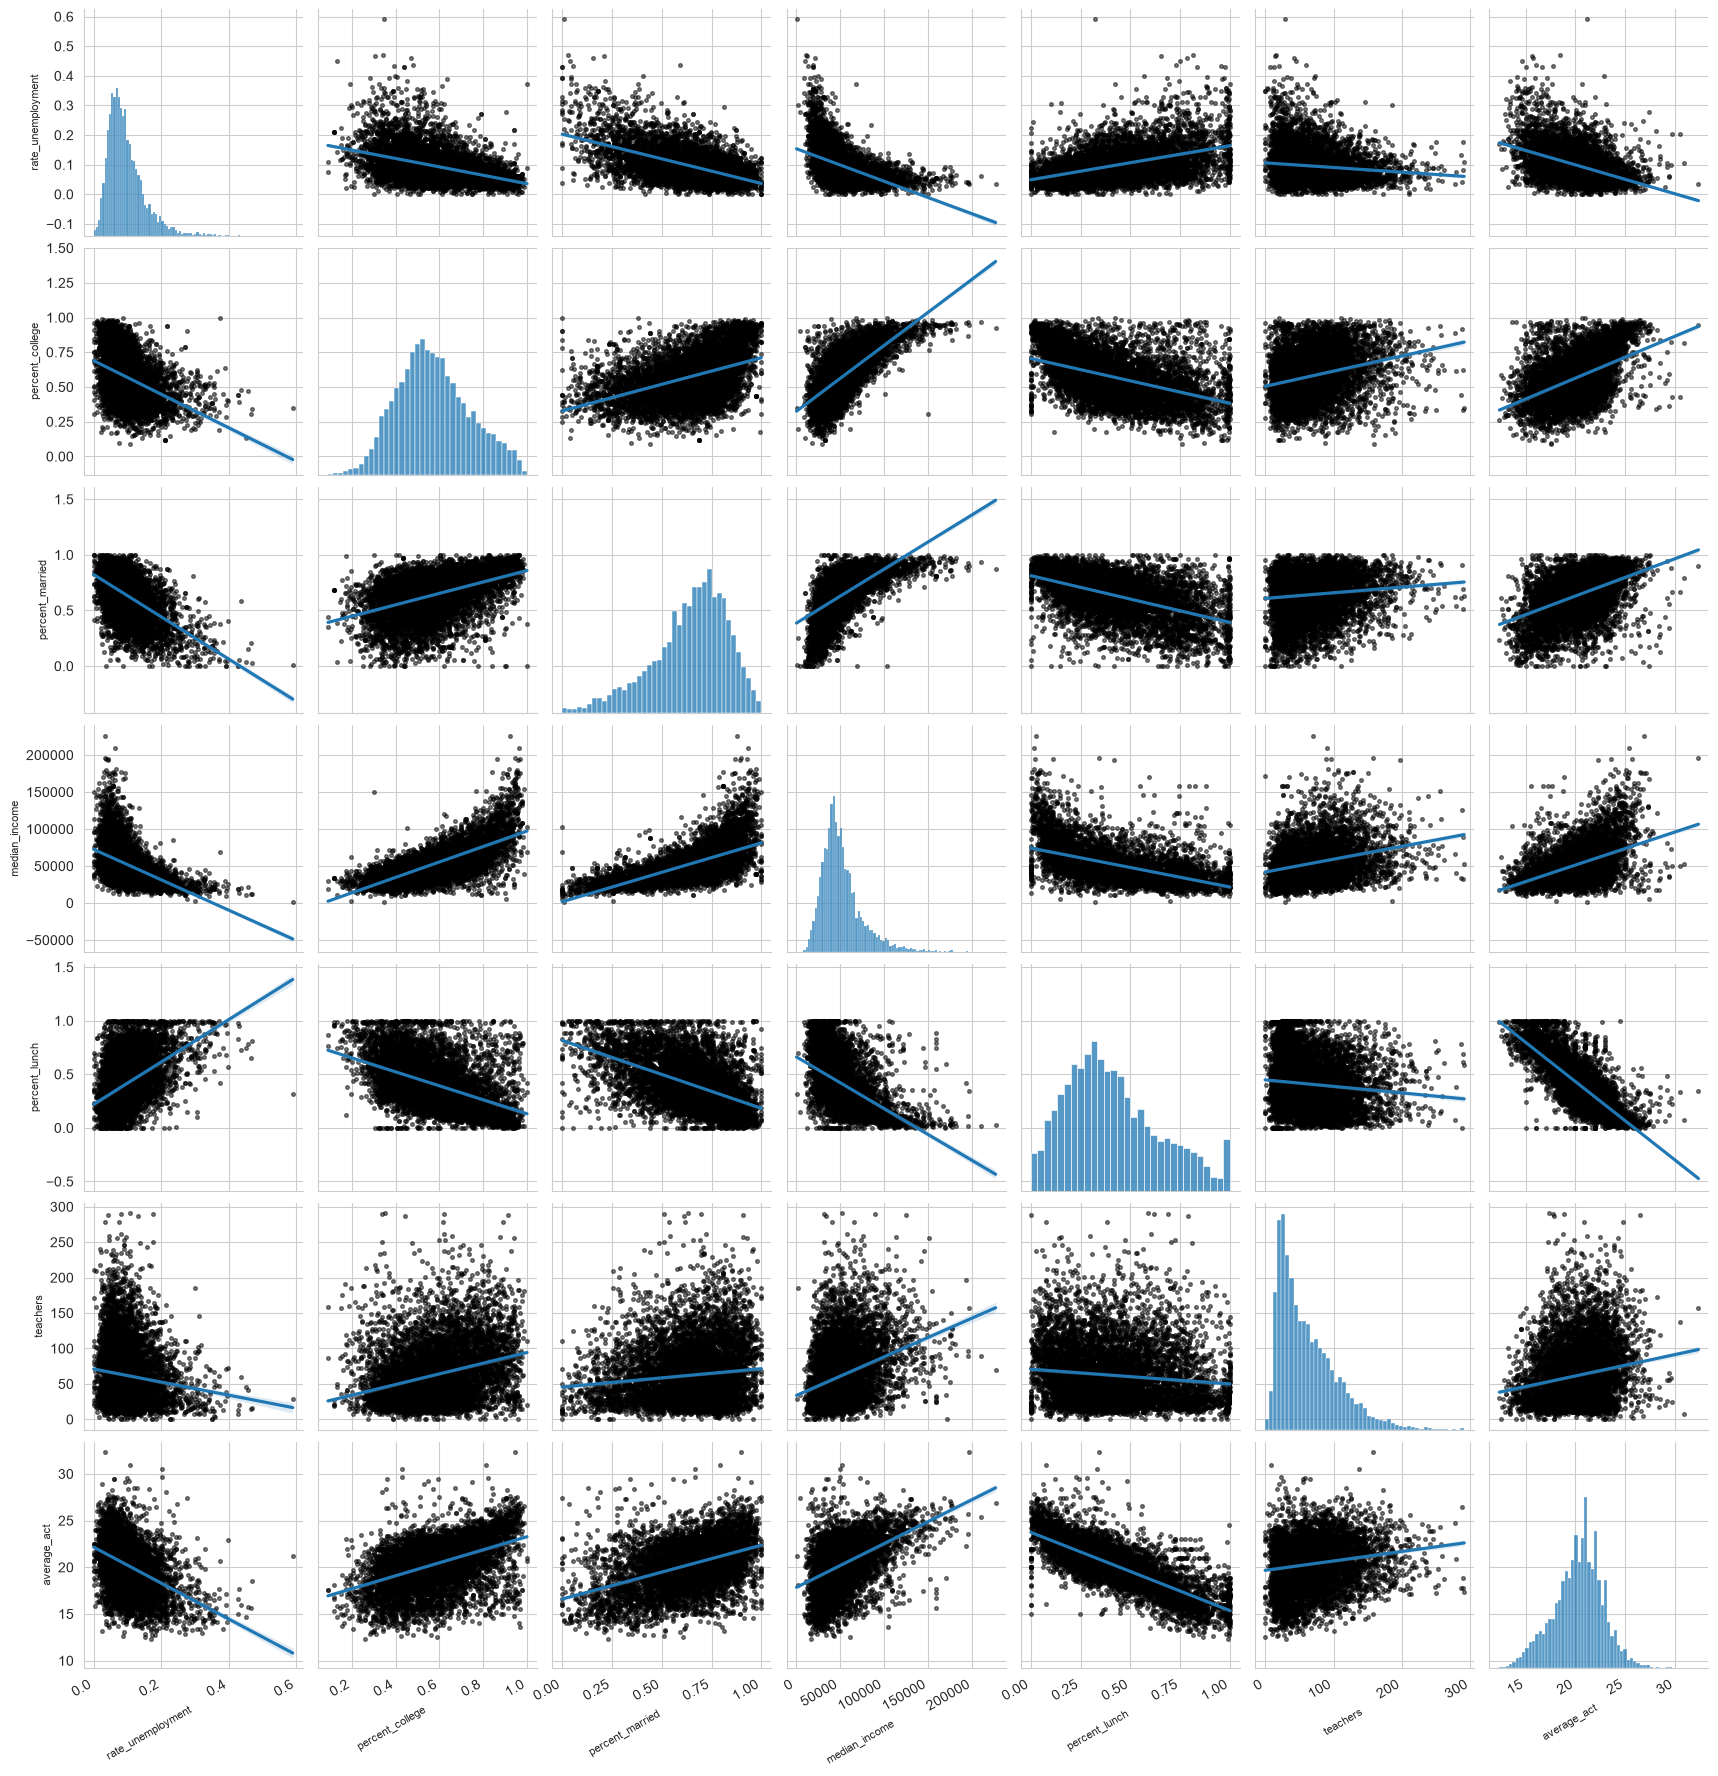

In [5]:
fig = sns.pairplot(
    data = df,
    vars = numerical_predictors + ['average_act'],
    kind = 'reg',
    plot_kws = {'scatter_kws': {'alpha': 0.5, 'color': 'k', 's': 7}}
)

for ax in fig.axes.flat:
    if ax.get_xlabel() == 'CT Median Household Income':
       ax.ticklabel_format(style = 'sci', axis = 'x', scilimits = (0,0)) # Apply scientific notation
    ax.set_xlabel(ax.get_xlabel(), fontsize = 8, rotation = 30, ha = 'right') # X-axis label size and rotation
    ax.set_ylabel(ax.get_ylabel(), fontsize = 8) # Y-axis label size

    # Rotate x-axis tick labels
    plt.setp(ax.get_xticklabels(), rotation = 30, ha = 'right')

plt.show()

### Identify outliers

We can use the interquartile range to identify outliers. This is also evident in boxplots of the data. Median incom and nummber of teachers are on a very different scale than the other predictors, so we will make three plots to explore the data.

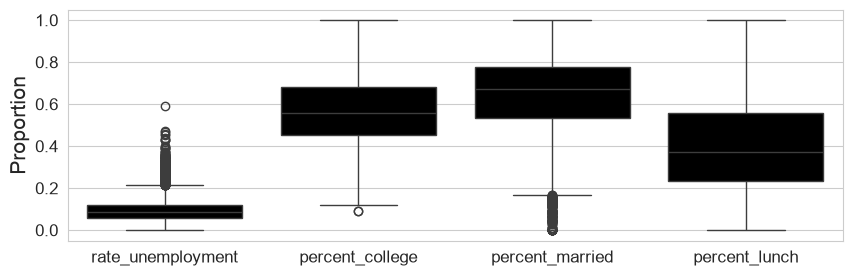

In [8]:
plt.figure(figsize = (10,3))

fractions = list(numerical_predictors)
fractions.remove('median_income')
fractions.remove('teachers')

sns.boxplot(data = df[fractions], color = 'k')

plt.ylabel('Proportion', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

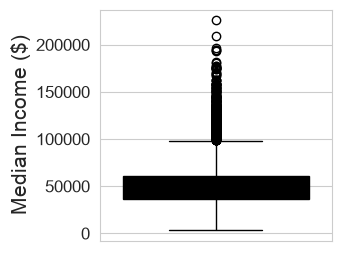

In [12]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['median_income'], color = 'k')

plt.ylabel('Median Income ($)', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

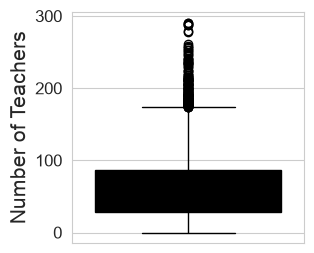

In [9]:
plt.figure(figsize = (3,3))

sns.boxplot(data = df['teachers'], color = 'k')

plt.ylabel('Number of Teachers', fontsize = 15)

plt.tick_params(labelsize = 12)

plt.show()

## Summary
1. The numerical predictors are related to average_act. The relationships appear roughly linear.
2. The numerical predictors are correlated with each other, suggesting that not all predictors will be necessary.
3. Some variables have skewed distributions, suggesting that transformations of input variables might be useful.
4. There are outliers in rate_unemployment, percent_college, percent_married, median_income, and teachers. None of these are obviously incorrect values; they likely reflect skewed distributions. We may consider applying something like a log transformation to these predictors as we explore different models.